In [5]:
   !pip install qiskit qiskit-aer matplotlib pandas numpy

In [6]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error

def make_noise_model(p):
    # with probability p, an X (bit-flip) error hits the qubit
    err = pauli_error([('X', p), ('I', 1 - p)])
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(err, ['id'])  # noise acts on the 'id' gate
    return nm

def unprotected(p, shots=1000):
    qc = QuantumCircuit(1, 1)
    qc.x(0)          # prepare |1>
    qc.id(0)         # <- the noisy step
    qc.measure(0, 0)
    sim = AerSimulator(noise_model=make_noise_model(p))
    tc = transpile(qc, sim, optimization_level=0)
    counts = sim.run(tc, shots=shots).result().get_counts()
    return counts.get('1', 0) / shots   # fidelity = fraction correct

print(unprotected(0.1))   # expect about 0.90

0.883


In [7]:
def protected(p, shots=4000):
    qc = QuantumCircuit(3, 1)
    qc.x(0)                       # prepare |1>
    qc.cx(0, 1); qc.cx(0, 2)      # ENCODE: copy onto 3 qubits
    qc.barrier()
    qc.id(0); qc.id(1); qc.id(2)  # NOISE hits all three
    qc.barrier()
    qc.cx(0, 1); qc.cx(0, 2)      # DECODE + detect
    qc.ccx(1, 2, 0)               # CORRECT: fix qubit 0 if both others flagged
    qc.measure(0, 0)
    sim = AerSimulator(noise_model=make_noise_model(p))
    tc = transpile(qc, sim, optimization_level=0)
    counts = sim.run(tc, shots=shots).result().get_counts()
    return counts.get('1', 0) / shots

print(protected(0.1))   # expect about 0.97

0.97325


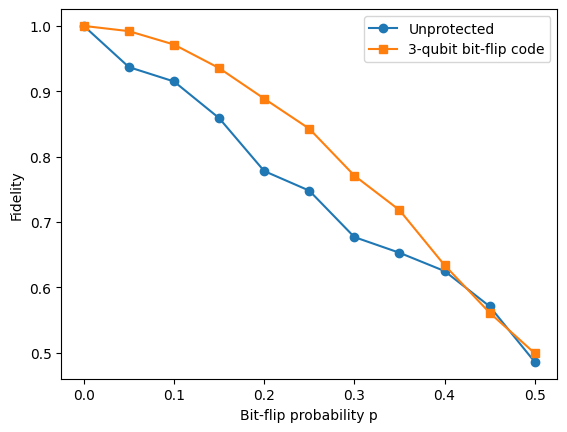

In [8]:
import numpy as np
import matplotlib.pyplot as plt

ps = np.linspace(0, 0.5, 11)
unp = [unprotected(p) for p in ps]
pro = [protected(p) for p in ps]

plt.plot(ps, unp, 'o-', label='Unprotected')
plt.plot(ps, pro, 's-', label='3-qubit bit-flip code')
plt.xlabel('Bit-flip probability p'); plt.ylabel('Fidelity')
plt.legend(); plt.show()

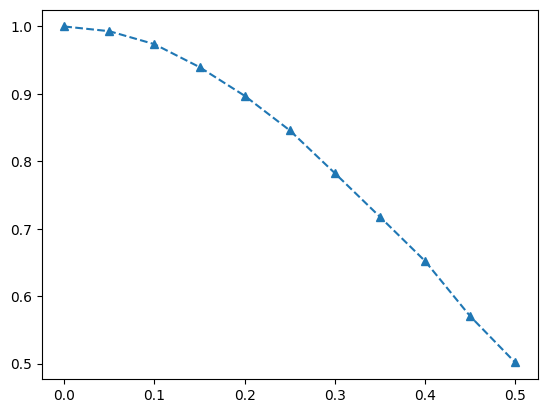

In [9]:
def classical_repetition(p, shots=4000):
    rng = np.random.default_rng(0)
    flips = rng.random((shots, 3)) < p        # which copies got flipped
    majority_wrong = flips.sum(axis=1) >= 2
    return 1 - majority_wrong.mean()

cl = [classical_repetition(p) for p in ps]
plt.plot(ps, cl, '^--', label='Classical repetition')

In [10]:
import pandas as pd
df = pd.read_csv('your_file.csv')
print(df.shape); print(df.columns.tolist())
print(df.describe())
print(df.corr(numeric_only=True))

FileNotFoundError: [Errno 2] No such file or directory: 'your_file.csv'

In [ ]:
import pandas as pd
df = pd.read_csv('your_file.csv')
print(df.shape); print(df.columns.tolist())
print(df.describe())
print(df.corr(numeric_only=True))

In [ ]:
!pip install kagglehub
import kagglehub, os
kagglehub.login()   # paste your Kaggle API token when prompted
path = kagglehub.competition_download("quantum")
print(path)
print(os.listdir(path))

In [ ]:
import pandas as pd
df = pd.read_csv(os.path.join(path, "train.csv"))
print(df.shape); print(df.columns.tolist())
print(df.describe())
print(df.corr(numeric_only=True))

In [ ]:
!pip install kagglehub
import kagglehub, os
kagglehub.login()   # paste your Kaggle API token when prompted
path = kagglehub.competition_download("quantum")
print(path)
print(os.listdir(path))

In [ ]:
import pandas as pd
df = pd.read_csv(os.path.join(path, "train.csv"))
print(df.shape); print(df.columns.tolist())
print(df.describe())
print(df.corr(numeric_only=True))

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error

# --- Step 1: pick a realistic noise level from the data ---
print(df.corr(numeric_only=True)['target'].sort_values())
p_real = df['gate_error_rate'].mean()
print("typical gate error rate:", p_real)

# --- circuits ---
def unprotected():
    qc = QuantumCircuit(1, 1)
    qc.x(0)            # logical |1>
    qc.id(0)           # noise acts here
    qc.measure(0, 0)
    return qc

def protected():
    qc = QuantumCircuit(3, 1)
    qc.x(0)
    qc.cx(0, 1); qc.cx(0, 2)        # encode
    qc.barrier()
    for q in range(3): qc.id(q)      # noise acts here
    qc.barrier()
    qc.cx(0, 1); qc.cx(0, 2)        # decode
    qc.ccx(1, 2, 0)                  # majority-vote correction
    qc.measure(0, 0)
    return qc

def run(qc, p, shots=4000):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(pauli_error([('X', p), ('I', 1 - p)]), ['id'])
    sim = AerSimulator(noise_model=nm)
    t = transpile(qc, sim, optimization_level=0)   # keeps the id gates
    counts = sim.run(t, shots=shots).result().get_counts()
    return counts.get('0', 0) / shots              # logical error rate (should read 1)

# --- sweep p from 0 to 0.5 ---
ps = np.linspace(0, 0.5, 26)
e_unprot = [run(unprotected(), p) for p in ps]
e_prot   = [run(protected(), p) for p in ps]
rng = np.random.default_rng(0)
e_class  = [(rng.random((4000, 3)) < p).sum(axis=1).__ge__(2).mean() for p in ps]
theory   = 3*ps**2 - 2*ps**3

# --- graph: fidelity vs noise ---
plt.plot(ps, 1-np.array(e_unprot), label='Unprotected')
plt.plot(ps, 1-np.array(e_prot),   label='Quantum 3-qubit code')
plt.plot(ps, 1-np.array(e_class),  '--', label='Classical repetition')
plt.plot(ps, 1-theory, ':', label='Theory 1-(3p²-2p³)')
plt.axvline(p_real, color='gray', lw=0.8)
plt.xlabel('bit-flip probability p'); plt.ylabel('fidelity'); plt.legend(); plt.show()

# --- trade-off table ---
rows = []
for name, qc, e in [('Unprotected', unprotected(), e_unprot), ('3-qubit code', protected(), e_prot)]:
    i = int(np.argmin(abs(ps - 0.1)))
    rows.append({'scheme': name, 'qubits': qc.num_qubits, 'depth': qc.depth(),
                 'gates': qc.size(), 'fidelity at p=0.1': 1 - e[i]})
print(pd.DataFrame(rows))

In [ ]:
def unprot_depth(d):
    qc = QuantumCircuit(1, 1); qc.x(0)
    for _ in range(d): qc.id(0)
    qc.measure(0, 0); return qc

def prot_depth(d):
    qc = QuantumCircuit(3, 1); qc.x(0)
    qc.cx(0, 1); qc.cx(0, 2)
    for _ in range(d):
        for q in range(3): qc.id(q)
    qc.cx(0, 1); qc.cx(0, 2); qc.ccx(1, 2, 0)
    qc.measure(0, 0); return qc

depths = [1, 5, 10, 20, 40, 60, 99]
fu = [1 - run(unprot_depth(d), p_real, 20000) for d in depths]
fp = [1 - run(prot_depth(d), p_real, 20000) for d in depths]
plt.plot(depths, fu, label='Unprotected'); plt.plot(depths, fp, label='3-qubit code')
plt.xlabel('number of noisy layers (circuit depth)'); plt.ylabel('fidelity'); plt.legend(); plt.show()

In [ ]:
import time
for name, qc in [('Unprotected', unprotected()), ('3-qubit code', protected())]:
    t0 = time.time(); run(qc, p_real, 20000); print(name, round(time.time() - t0, 3), 's')